In [17]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import xarray as xr
import pandas as pd
import numpy as np

PROJECT_ROOT = Path().resolve().parent.parent
sys.path.append(str(PROJECT_ROOT))

In [ ]:
import src.CAMP2Ex as cx
plt.style.use('seaborn-v0_8-talk')

In [18]:
obs_path = PROJECT_ROOT / 'data' / 'interim' / 'MISR_RAD_O105254_P117_R00275_X17774487_18126212_Y0122787_0421712.nc'
obs = xr.load_dataset(obs_path).sel(camera='AN')

In [ ]:
RAW_DATA = PROJECT_ROOT / 'data' / 'raw'
nav_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'CAMP2EX-MetNav_P3B_20191001_R0.ict'
fcdp_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'PaulLawson' / 'CAMP2Ex-FCDP_P3B_20191001_R1.ict'
tds_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'PaulLawson' / 'CAMP2Ex-2DS10_P3B_20191001_R0.ict'
p3 = cx.load_FCDP_2DS(fcdp_file, tds_file, nav_file, breakpoint=40, resample='2s')

start_time = pd.to_datetime('2019-10-02 00:00:00')
end_time = pd.to_datetime('2019-10-02 02:00:00')

p3_subset = p3[
    # (p3['N_L'] > 10000)
    (p3['ext_km'] > 0.3)
    & (p3.index > start_time)
    & (p3.index < end_time)
    & (p3['GPS_Altitude'] < 1250)
]

/data/gdi/b/johntl3/LundstromPub2025/src/CAMP2Ex.py:110: RuntimeWarning: invalid value encountered in true_divide
  Re = np.sum(n * r**3, axis=-1) / np.sum(n * r**2, axis=-1)


In [ ]:
som_center_x = 0.5*(17950487+18003012)
som_center_y = 0.5*(193187+245712)
som_ulc_x = som_center_x - 8800
som_lrc_x = som_center_x + 8800
som_ulc_y = som_center_y - 8800
som_lrc_y = som_center_y + 8800
ulc = obs.sel(som_x=som_ulc_x, som_y=som_ulc_y, method='nearest')
lrc = obs.sel(som_x=som_lrc_x, som_y=som_lrc_y, method='nearest')

Text(0, 0.5, 'Latitude')

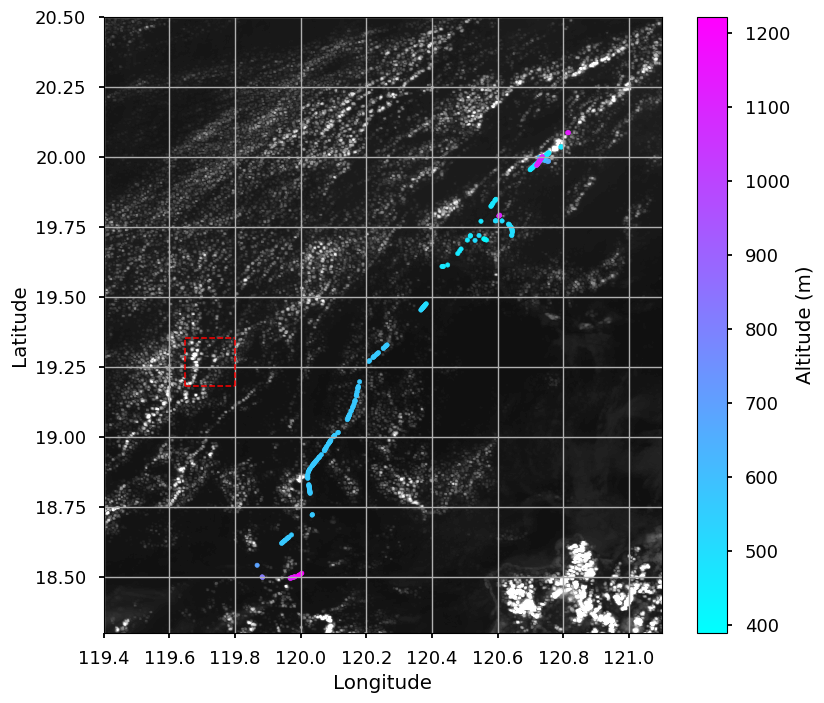

In [53]:
brf_kwargs = {
    'cmap': 'gray',
    'vmin': 0.0,
    'vmax': 0.4,
    'levels': np.linspace(0, 0.4, 100)
}
box_kwargs = {'ls':'--', 'lw':1.1, 'c':'r'}
scat_kwargs = {
    's': 10,
    'cmap':'cool'
}

plt.style.use('seaborn-v0_8-talk')
f, ax = plt.subplots(1, 1, figsize=(9,8))

p = ax.tricontourf(
    np.ravel(obs.lon.data),
    np.ravel(obs.lat.data),
    np.ravel(obs.brf.data),
    **brf_kwargs
)

s = ax.scatter(
    p3_subset['Longitude'], 
    p3_subset['Latitude'], 
    c=p3_subset['GPS_Altitude'], 
    **scat_kwargs
)
plt.colorbar(s, label='Altitude (m)')

ax.plot([ulc.lon, ulc.lon], [lrc.lat, ulc.lat], **box_kwargs) # left
ax.plot([lrc.lon, lrc.lon], [lrc.lat, ulc.lat], **box_kwargs) # right
ax.plot([ulc.lon, lrc.lon], [ulc.lat, ulc.lat], **box_kwargs) # top
ax.plot([ulc.lon, lrc.lon], [lrc.lat, lrc.lat], **box_kwargs) # bottom

ax.grid(lw=1)

ax.set_xlim([119.4,121.1])
ax.set_ylim([18.3,20.5])

ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
